<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rows: 150  Features: 4  Classes: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'] 

Train size: 120  Test size: 30 

K    Accuracy
1    96.67%
3    93.33%
5    93.33%
7    93.33%
9    96.67%
11   96.67%

Confusion Matrix (K = 5, rows = actual, columns = predicted):
                 Iris-setosa  Iris-versicolor  Iris-virginica
Iris-setosa                7                0               0
Iris-versicolor            0               11               0
Iris-virginica             0                2              10

Accuracy (K = 5): 93.33%

New flower (sepal_length, sepal_width, petal_length, petal_width): [5.9, 3.0, 5.1, 1.8]
Predicted species: Iris-virginica


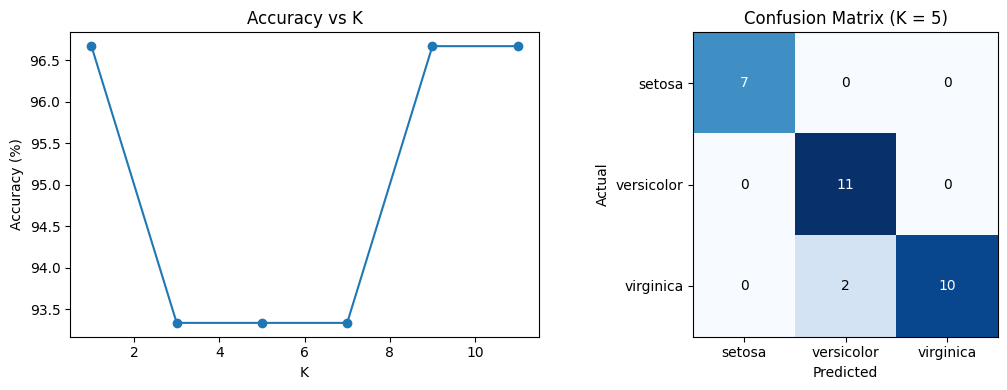

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Dataset: Iris - UCI Machine Learning Repository (program12.csv, used as it is, no header row)

# ---- 1. Load CSV ----
cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
df = pd.read_csv('program12.csv', header=None, names=cols)
X = df.iloc[:, :-1].values.astype(float)
y = df['species'].values
classes = sorted(set(y))
print("Rows:", len(df), " Features:", X.shape[1], " Classes:", classes, "\n")

# ---- 2. Normalize inputs (0 to 1) ----
xmin, xmax = X.min(axis=0), X.max(axis=0)
Xn = (X - xmin) / (xmax - xmin)

# ---- 3. Train / test split (80% / 20%) ----
np.random.seed(42)
idx = np.random.permutation(len(Xn))
split = int(0.8 * len(Xn))
Xtr, Xte = Xn[idx[:split]], Xn[idx[split:]]
ytr, yte = y[idx[:split]], y[idx[split:]]
print("Train size:", len(Xtr), " Test size:", len(Xte), "\n")

# ---- 4. K-NN algorithm ----
def knn_predict(x, k):
    dists = np.sqrt(np.sum((Xtr - x) ** 2, axis=1))      # distance to every training flower
    nearest = np.argsort(dists)[:k]                      # k closest flowers
    return Counter(ytr[nearest]).most_common(1)[0][0]    # majority vote

# ---- 5. Accuracy for different values of K ----
ks = [1, 3, 5, 7, 9, 11]
accs = []
print("K    Accuracy")
for k in ks:
    preds = np.array([knn_predict(x, k) for x in Xte])
    acc = np.mean(preds == yte) * 100
    accs.append(acc)
    print(f"{k:<4} {acc:.2f}%")

# ---- 6. Confusion matrix for K = 5 ----
k = 5
preds = np.array([knn_predict(x, k) for x in Xte])
n = len(classes)
cm = np.zeros((n, n), dtype=int)
for a, p in zip(yte, preds):
    cm[classes.index(a), classes.index(p)] += 1

print(f"\nConfusion Matrix (K = {k}, rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=classes, columns=classes))
print(f"\nAccuracy (K = {k}): {np.trace(cm) / cm.sum() * 100:.2f}%")

# ---- 7. Classify a new flower ----
new_flower = np.array([5.9, 3.0, 5.1, 1.8])              # raw measurements in cm
new_norm = (new_flower - xmin) / (xmax - xmin)
print("\nNew flower (sepal_length, sepal_width, petal_length, petal_width):", new_flower.tolist())
print("Predicted species:", knn_predict(new_norm, k))

# ---- 8. Plots ----
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, accs, marker='o')
ax[0].set_xlabel('K')
ax[0].set_ylabel('Accuracy (%)')
ax[0].set_title('Accuracy vs K')

ax[1].imshow(cm, cmap='Blues')
ax[1].set_xticks(range(n))
ax[1].set_xticklabels([c.replace('Iris-', '') for c in classes])
ax[1].set_yticks(range(n))
ax[1].set_yticklabels([c.replace('Iris-', '') for c in classes])
ax[1].set_xlabel('Predicted')
ax[1].set_ylabel('Actual')
ax[1].set_title(f'Confusion Matrix (K = {k})')

for i in range(n):
    for j in range(n):
        ax[1].text(j, i, cm[i, j], ha='center', va='center',
                   color='white' if cm[i, j] > cm.max() / 2 else 'black')

plt.tight_layout()
plt.show()